# Regresion lineal: costos de seguros medicos

Objetivo: predecir `charges` (costo anual del seguro medico, en dolares) a partir de `age`, `sex`, `bmi`, `children`, `smoker` y `region`.

Pasos del proyecto:
1. Carga del dataset y primera revision.
2. EDA completo (con division train/test previa).
3. Modelo de regresion lineal con parametros por defecto.
4. Optimizacion del modelo si los resultados no son satisfactorios.

## 1. Carga y primera revision de los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("../medical_insurance_cost.csv")
print(df.shape)
df.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### Estructura, valores nulos y duplicados

In [3]:
df.info()
print("Nulos por columna:")
print(df.isna().sum())
print("Filas duplicadas:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
Nulos por columna:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Filas duplicadas: 1


### Resumen estadistico y categorias

In [4]:
display(df.describe())
for col in ["sex", "smoker", "region"]:
    print(df[col].value_counts(), "\n")

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


sex
male      676
female    662
Name: count, dtype: int64 

smoker
no     1064
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64 



### Conclusiones de la primera revision

El dataset tiene 1338 filas y 7 columnas, sin valores nulos y con los tipos de dato correctos. Hay una unica fila duplicada exacta, que eliminaremos para no dar doble peso a un mismo registro. `sex` y `region` estan bien balanceadas, mientras que `smoker` esta desbalanceada (20,5% de fumadores). `charges` tiene la media (13270) muy por encima de la mediana (9382) y un maximo de 63770, lo que sugiere una distribucion asimetrica a la derecha con valores extremos. Esto se analizara graficamente en el EDA y puede afectar al cumplimiento de los supuestos de la regresion lineal.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(1337, 7)


## 2. Division train/test y analisis exploratorio

Dividimos los datos antes de explorar: el analisis se hace solo con el conjunto de entrenamiento para que el test siga siendo una evaluacion honesta. Se estratifica por `smoker` para mantener la misma proporcion de fumadores en ambos conjuntos.

In [6]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="charges")
y = df["charges"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=X["smoker"]
)
train = X_train.assign(charges=y_train)
print(train.shape, X_test.shape)
print(train["smoker"].value_counts(normalize=True).round(3))

(1069, 7) (268, 6)
smoker
no     0.795
yes    0.205
Name: proportion, dtype: float64


### Distribucion de la variable objetivo

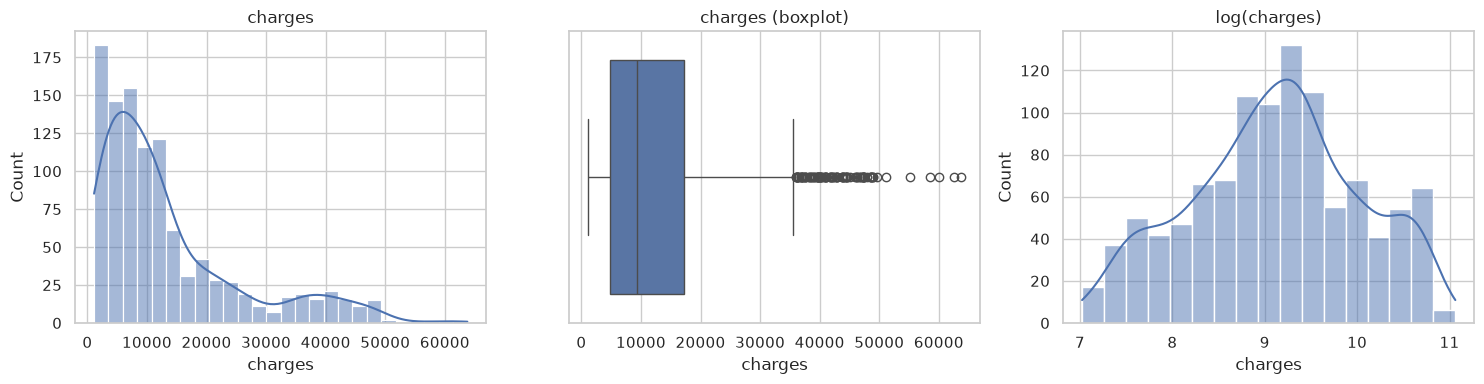

Asimetria charges: 1.52
Asimetria log(charges): -0.11


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(train["charges"], kde=True, ax=axes[0])
axes[0].set_title("charges")
sns.boxplot(x=train["charges"], ax=axes[1])
axes[1].set_title("charges (boxplot)")
sns.histplot(np.log(train["charges"]), kde=True, ax=axes[2])
axes[2].set_title("log(charges)")
plt.tight_layout()
plt.show()
print("Asimetria charges:", round(train["charges"].skew(), 2))
print("Asimetria log(charges):", round(np.log(train["charges"]).skew(), 2))

### Variables numericas frente a charges

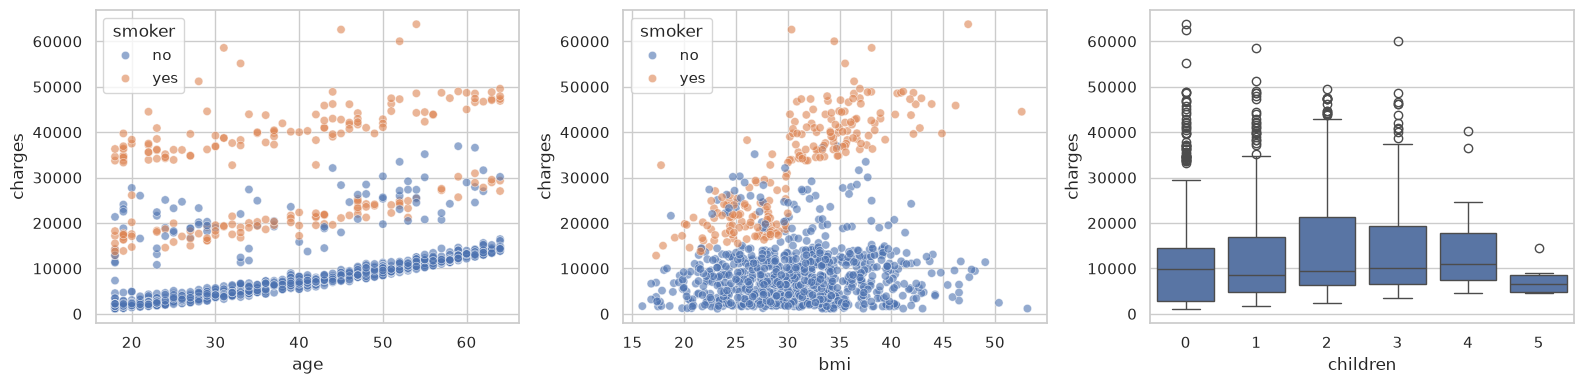

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=train, x="age", y="charges", hue="smoker", alpha=0.6, ax=axes[0])
sns.scatterplot(data=train, x="bmi", y="charges", hue="smoker", alpha=0.6, ax=axes[1])
sns.boxplot(data=train, x="children", y="charges", ax=axes[2])
plt.tight_layout()
plt.show()

### Variables categoricas frente a charges

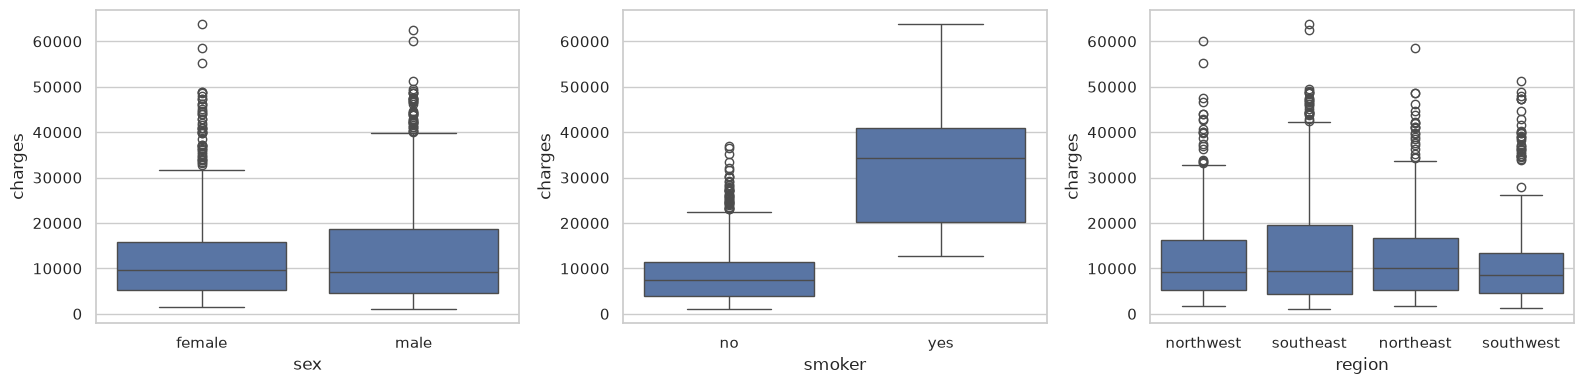

        count     mean   median
smoker                         
no        850   8568.0   7352.0
yes       219  31938.0  34254.0


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["sex", "smoker", "region"]):
    sns.boxplot(data=train, x=col, y="charges", ax=ax)
plt.tight_layout()
plt.show()
print(train.groupby("smoker")["charges"].agg(["count", "mean", "median"]).round(0))

### Correlaciones

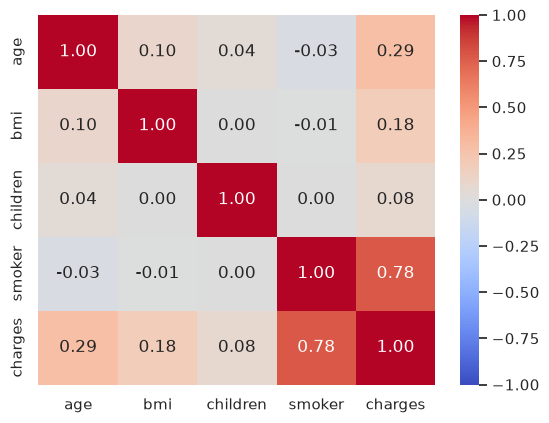

In [10]:
corr = train.assign(smoker=(train["smoker"] == "yes").astype(int))[["age", "bmi", "children", "smoker", "charges"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

### Conclusiones del EDA

El conjunto de entrenamiento mantiene la proporcion de fumadores (20,5%). `charges` es asimetrica a la derecha (asimetria 1,52) y el logaritmo la corrige casi por completo (-0,11), lo que sugiere probar una transformacion logaritmica del objetivo. `smoker` es con diferencia la variable mas influyente: los fumadores pagan de media unas 3,7 veces mas (31938 frente a 8568) y su correlacion con `charges` es 0,78. `age` muestra una relacion creciente y casi lineal (correlacion 0,29). `bmi` tiene poca correlacion global (0,18), pero en los fumadores el coste salta cuando `bmi` supera aproximadamente 30, lo que indica una interaccion entre `smoker` y `bmi` que un modelo lineal simple no captura. `children`, `sex` y `region` apenas se relacionan con `charges`. Los predictores casi no estan correlacionados entre si (maximo 0,10), por lo que no se espera multicolinealidad. En resumen, el modelo lineal base deberia funcionar razonablemente, pero la interaccion smoker-bmi y la asimetria del objetivo son las principales mejoras a explorar en la fase de optimizacion.

## 3. Modelo base: regresion lineal con parametros por defecto

Las variables categoricas (`sex`, `smoker`, `region`) se codifican con one-hot, eliminando una categoria de cada una para evitar colinealidad perfecta. El rendimiento se mide con validacion cruzada sobre el conjunto de entrenamiento; el conjunto de test se usara una sola vez al final.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

cat_cols = ["sex", "smoker", "region"]
prep = ColumnTransformer(
    [("cat", OneHotEncoder(drop="first"), cat_cols)],
    remainder="passthrough",
)
base = Pipeline([("prep", prep), ("model", LinearRegression())])
base.fit(X_train, y_train)

names = base.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(base.named_steps["model"].coef_, index=names).round(1)
print("Intercepto:", round(base.named_steps["model"].intercept_, 1))
print(coefs)

Intercepto: -11593.8
cat__sex_male             -258.0
cat__smoker_yes          23750.0
cat__region_northwest     -361.2
cat__region_southeast    -1193.7
cat__region_southwest    -1031.8
remainder__age             255.9
remainder__bmi             330.8
remainder__children        626.1
dtype: float64


### Rendimiento con validacion cruzada

In [12]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)
res = cross_validate(
    base, X_train, y_train, cv=cv,
    scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"},
)
print("R2   :", round(res["test_r2"].mean(), 3), "+/-", round(res["test_r2"].std(), 3))
print("RMSE :", round(-res["test_rmse"].mean(), 0))
print("MAE  :", round(-res["test_mae"].mean(), 0))

R2   : 0.722 +/- 0.036
RMSE : 6297.0
MAE  : 4393.0


### Diagnostico de supuestos con los residuos

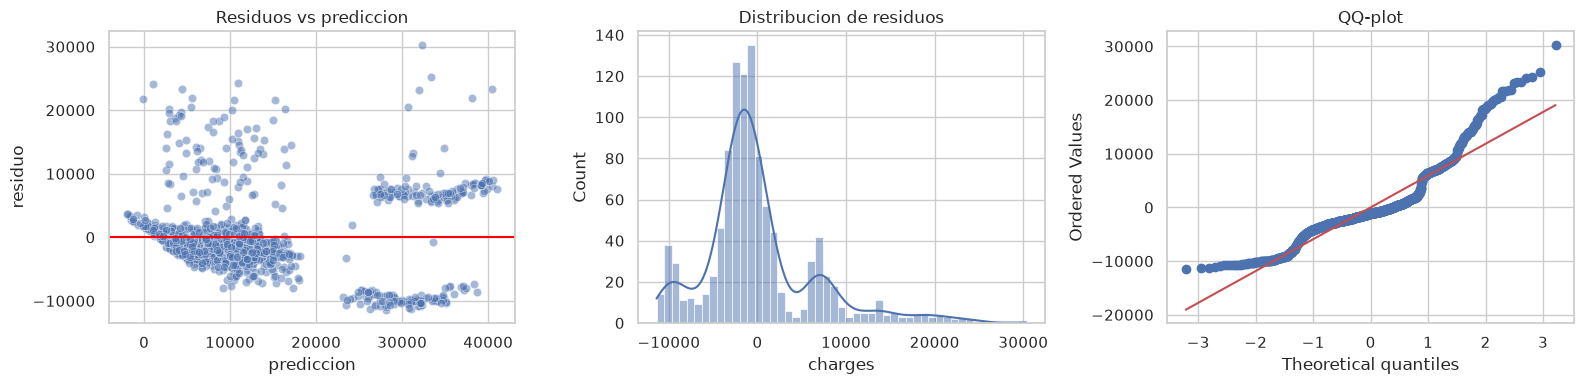

In [13]:
import scipy.stats as stats

pred = base.predict(X_train)
resid = y_train - pred
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(x=pred, y=resid, alpha=0.5, ax=axes[0])
axes[0].axhline(0, color="red")
axes[0].set_xlabel("prediccion")
axes[0].set_ylabel("residuo")
axes[0].set_title("Residuos vs prediccion")
sns.histplot(resid, kde=True, ax=axes[1])
axes[1].set_title("Distribucion de residuos")
stats.probplot(resid, dist="norm", plot=axes[2])
axes[2].set_title("QQ-plot")
plt.tight_layout()
plt.show()

### Conclusiones del modelo base

El modelo base alcanza un R2 de 0,72 (+/- 0,04) en validacion cruzada, con un RMSE de 6297 y un MAE de 4393 dolares. Los coeficientes son coherentes con el EDA: ser fumador anade unos 23750 dolares al coste previsto, y cada ano de edad, cada punto de bmi y cada hijo suman aproximadamente 256, 331 y 626 dolares; sexo y region tienen un efecto pequeno. Sin embargo, el diagnostico de residuos muestra que no se cumplen varios supuestos: los residuos forman grupos claramente separados (los fumadores con bmi alto quedan subestimados y los de bmi bajo sobreestimados, por la interaccion smoker-bmi que el modelo no recoge), hay predicciones negativas, la varianza no es constante y los residuos se alejan de la normalidad (asimetria y colas pesadas en el QQ-plot). Por tanto los resultados son aceptables pero mejorables, y esta justificado pasar a la fase de optimizacion probando una variable de interaccion smoker-bmi, una transformacion logaritmica del objetivo y modelos regularizados.

## 4. Optimizacion del modelo

Se comparan varias mejoras con la misma validacion cruzada sobre train: variables de interaccion (smoker x bmi, obesidad), un termino cuadratico de la edad, una transformacion logaritmica del objetivo y modelos regularizados (Ridge y Lasso, con datos estandarizados). Las variables nuevas se calculan dentro del pipeline, de modo que se aplican igual a train y a test sin fuga de informacion.

In [14]:
from sklearn.preprocessing import FunctionTransformer, StandardScaler

def add_features(d, interaccion_bmi=False, obeso=False, edad2=False):
    d = d.copy()
    fuma = (d["smoker"] == "yes").astype(int)
    if interaccion_bmi:
        d["smoker_x_bmi"] = fuma * d["bmi"]
    if obeso:
        d["obeso"] = (d["bmi"] >= 30).astype(int)
        d["smoker_x_obeso"] = fuma * d["obeso"]
    if edad2:
        d["age2"] = d["age"] ** 2
    return d

def make_model(model, scale=False, **feat_kw):
    prep = ColumnTransformer(
        [("cat", OneHotEncoder(drop="first"), cat_cols)],
        remainder="passthrough",
    )
    steps = [("feat", FunctionTransformer(add_features, kw_args=feat_kw)), ("prep", prep)]
    if scale:
        steps.append(("scale", StandardScaler()))
    return Pipeline(steps + [("model", model)])

### Comparacion de candidatos

In [15]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import RidgeCV, LassoCV

candidatos = {
    "Base": make_model(LinearRegression()),
    "+ smoker x bmi": make_model(LinearRegression(), interaccion_bmi=True),
    "+ obeso y smoker x obeso": make_model(LinearRegression(), obeso=True),
    "+ obeso, smoker x obeso y age^2": make_model(LinearRegression(), obeso=True, edad2=True),
    "log(charges) + obeso": TransformedTargetRegressor(
        make_model(LinearRegression(), obeso=True), func=np.log, inverse_func=np.exp),
    "RidgeCV + obeso": make_model(RidgeCV(alphas=np.logspace(-3, 3, 30)), scale=True, obeso=True),
    "LassoCV + obeso": make_model(LassoCV(cv=5, random_state=42, max_iter=50000), scale=True, obeso=True),
}
filas = []
for nombre, modelo in candidatos.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring={
        "r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"})
    filas.append({"modelo": nombre, "R2": r["test_r2"].mean(),
                  "RMSE": -r["test_rmse"].mean(), "MAE": -r["test_mae"].mean()})
pd.DataFrame(filas).round(3)

,modelo,R2,RMSE,MAE
0,Base,0.722,6297.118,4392.589
1,+ smoker x bmi,0.819,5050.490,3132.983
2,+ obeso y smoker x obeso,0.842,4715.179,2694.463
3,"+ obeso, smoker x obeso y age^2",0.846,4662.394,2648.723
4,log(charges) + obeso,0.469,8764.387,4256.762
5,RidgeCV + obeso,0.843,4714.410,2700.790
6,LassoCV + obeso,0.842,4717.015,2719.781


### Conclusiones de la optimizacion

Las mejoras que funcionan son las variables de interaccion: anadir una marca de obesidad (bmi >= 30) y su interaccion con smoker sube el R2 en validacion cruzada de 0,72 a 0,84 y reduce el RMSE de 6297 a 4715 dolares, ya que captura el salto de coste de los fumadores obesos que el modelo base no recogia. El termino age^2 apenas aporta (R2 0,846 frente a 0,842), una diferencia inferior a la variabilidad entre particiones, por lo que se descarta en favor del modelo mas simple. Los modelos regularizados Ridge y Lasso rinden igual que la regresion lineal ordinaria (0,843 y 0,842), lo que indica que no hay sobreajuste que corregir con pocas variables y suficientes datos. La transformacion logaritmica del objetivo, pese a corregir la asimetria, empeora el RMSE (8764) y el R2 (0,47) medidos en dolares, asi que tambien se descarta. El modelo final elegido es una regresion lineal con las variables originales mas obeso y smoker x obeso.

## 5. Modelo final y evaluacion en test

El modelo final se ajusta con todo el conjunto de entrenamiento y se evalua una unica vez en test, junto al modelo base, para cuantificar la mejora.

In [16]:
final = make_model(LinearRegression(), obeso=True)
final.fit(X_train, y_train)

names = final.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(final.named_steps["model"].coef_, index=names).round(1)
print("Intercepto:", round(final.named_steps["model"].intercept_, 1))
print(coefs)

Intercepto: -3621.0
cat__sex_male                 -629.7
cat__smoker_yes              13155.2
cat__region_northwest         -362.9
cat__region_southeast         -812.9
cat__region_southwest        -1532.6
remainder__age                 257.6
remainder__bmi                  88.6
remainder__children            616.7
remainder__obeso              -631.7
remainder__smoker_x_obeso    20066.9
dtype: float64


### Diagnostico de residuos del modelo final

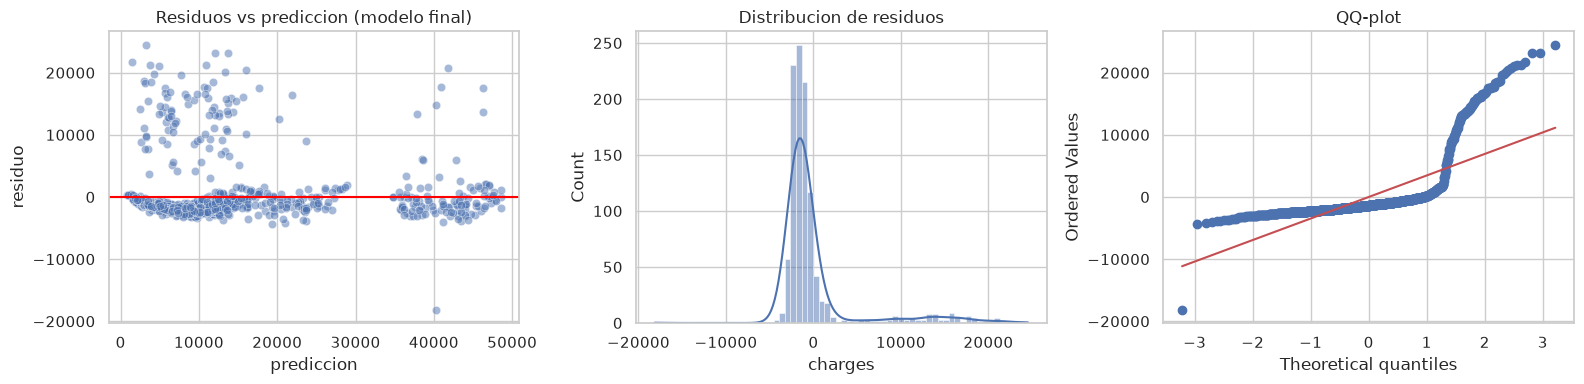

In [17]:
pred_f = final.predict(X_train)
resid_f = y_train - pred_f
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(x=pred_f, y=resid_f, alpha=0.5, ax=axes[0])
axes[0].axhline(0, color="red")
axes[0].set_xlabel("prediccion")
axes[0].set_ylabel("residuo")
axes[0].set_title("Residuos vs prediccion (modelo final)")
sns.histplot(resid_f, kde=True, ax=axes[1])
axes[1].set_title("Distribucion de residuos")
stats.probplot(resid_f, dist="norm", plot=axes[2])
axes[2].set_title("QQ-plot")
plt.tight_layout()
plt.show()

### Evaluacion en test: modelo base frente a modelo final

In [18]:
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

filas = []
for nombre, modelo in {"Base": base, "Final": final}.items():
    p = modelo.predict(X_test)
    filas.append({
        "modelo": nombre,
        "R2": r2_score(y_test, p),
        "RMSE": root_mean_squared_error(y_test, p),
        "MAE": mean_absolute_error(y_test, p),
        "predicciones negativas": int((p < 0).sum()),
    })
pd.DataFrame(filas).round(3)

,modelo,R2,RMSE,MAE,predicciones negativas
0,Base,0.820,5086.880,3592.793,3
1,Final,0.918,3439.587,2139.779,0


### Conclusiones finales

El modelo final, una regresion lineal con las variables originales mas la marca de obesidad (bmi >= 30) y su interaccion con smoker, mejora de forma clara al modelo base en el conjunto de test: el R2 sube de 0,82 a 0,92, el RMSE baja de 5087 a 3440 dolares y el MAE de 3593 a 2140, y desaparecen las predicciones negativas. Los coeficientes indican que ser fumador es el factor dominante y que su efecto se multiplica en personas obesas (unos 33200 dolares adicionales frente a unos 13200 en no obesas), mientras que cada ano de edad suma unos 258 dolares y cada hijo unos 617; sexo y region tienen un efecto menor. El diagnostico de residuos muestra que la interaccion eliminaba los grupos separados del modelo base, pero persisten limitaciones: los errores no son normales (cola derecha pesada) ni de varianza constante, y hay un grupo de clientes no fumadores con costes muy superiores a los previstos, probablemente por factores no recogidos en el dataset. Por ello el modelo es adecuado para estimar el coste medio esperado, pero no para construir intervalos de confianza fiables ni para inferencia estadistica. El R2 en test (0,92) es superior al de validacion cruzada (0,84), lo que probablemente se deba a que este conjunto de test contiene menos casos extremos; la mejora respecto al modelo base es consistente en ambos.